# Crime and London housing prices: M1-M7 using the original dataset

Run the original-data audit and all M1-M7 regressions first. M2-M4 and M6-M7 use supplied current annual crime; only M5 uses previous-calendar-year crime. The external monthly MPS file is processed separately at the very end and does not affect these regressions. No borough-year fixed effects are included.

Important: supplied violent crime is zero throughout 2014-2015. Those values are retained as supplied, not verified as true zeros. Treat resulting violence estimates cautiously; the final monthly section helps investigate the discrepancy.


## 0. Setup and load the original transactions

In [1]:
from pathlib import Path

try:
    from google.colab import drive
except ImportError:
    # Local project: both input files are directly inside project_data/.
    ROOT = Path.cwd()
    INPUT_DIR = ROOT / 'project_data'
else:
    # Google Colab: mount Drive before accessing the project files.
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/HE3027 Project')
    INPUT_DIR = ROOT / 'data'

DATA = INPUT_DIR / 'land_registry_crime.dta'
MONTHLY_FILE = INPUT_DIR / 'MPS LSOA Level Crime (Historical).csv'
OUT = INPUT_DIR / 'original_crime_models_outputs'

for input_file in [DATA]:
    if not input_file.is_file():
        raise FileNotFoundError(f'Input file not found: {input_file}')
OUT.mkdir(parents=True, exist_ok=True)

print('Project:', ROOT)
print('Transaction file:', DATA)
print('Monthly file:', MONTHLY_FILE)
print('Outputs:', OUT)

Project: C:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project
Transaction file: C:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project\project_data\land_registry_crime.dta
Monthly file: C:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project\project_data\MPS LSOA Level Crime (Historical).csv
Outputs: C:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project\project_data\original_crime_models_outputs


In [2]:
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
CRIMES = ['allcrime', 'violent_crime', 'propertycrime']
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)

def table(data, filename):
    """Save the complete table and display a compact preview."""
    data.to_csv(OUT / (filename + '.csv'))
    display(data.head(20) if len(data) > 20 else data)
    if len(data) > 20:
        print(f'Showing 20 of {len(data)} rows; the complete table is saved as {filename}.csv.')

VARIABLE_LABELS = {
    'detached_dum': 'Detached (relative to flat)',
    'semi_d_dum': 'Semi-detached (relative to flat)',
    'terrace_dum': 'Terraced (relative to flat)',
    'freehold': 'Freehold',
    'newbuild': 'New build',
    'tube_distnear_km': 'Distance to tube station (km)',
    'bus_distnear_km': 'Distance to bus stop (km)',
    'thamesriv_dist_km': 'Distance to Thames (km)',
    'Nearest_Park_dist_km': 'Distance to park (km)',
    'dist_to_cbd': 'Distance to CBD (km)',
    'Bus_stopscount_200m': 'Bus stops within 200m',
    'heritage_count_200m': 'Heritage buildings within 200m',
    'percent_noedu': 'Residents without qualifications',
    'percent_minorities': 'Minority residents',
    'lone_hh': 'Lone-parent households',
    'lnpay': 'Log borough annual pay',
    'jobdensity': 'Borough job density',
    'hoursworked': 'Borough weekly hours worked',
    'unemployment': 'Borough unemployment',
}

def coefficient_inference(coefficients, results):
    """Compute inference for every coefficient from its saved clustered SE."""
    keys = [name for name in ['panel', 'model', 'crime', 'measure', 'timing']
            if name in coefficients and name in results]
    metadata = results[keys + ['clusters']]
    enriched = coefficients.drop(columns=['clusters', 't', 'p', 'ci_low', 'ci_high'], errors='ignore')
    enriched = enriched.merge(metadata, on=keys, how='left', validate='many_to_one')
    if enriched.clusters.isna().any():
        raise ValueError('Coefficient rows could not be matched to regression metadata.')
    degrees_freedom = enriched.clusters - 1
    enriched['t'] = enriched.beta / enriched.se
    enriched['p'] = 2 * stats.t.sf(np.abs(enriched.t), degrees_freedom)
    critical = stats.t.ppf(0.975, degrees_freedom)
    enriched['ci_low'] = enriched.beta - critical * enriched.se
    enriched['ci_high'] = enriched.beta + critical * enriched.se
    return enriched

def show_models(results, filename, coefficient_filename):
    """Show one expandable table per model with crime AND control coefficients."""
    from html import escape
    from IPython.display import HTML

    results.to_csv(OUT / (filename + '.csv'), index=False)
    coefficients = coefficient_inference(pd.read_csv(OUT / coefficient_filename), results)
    coefficients.to_csv(OUT / coefficient_filename, index=False)
    cards = []

    def number(value):
        if pd.isna(value):
            return '—'
        if value != 0 and abs(value) < 0.0001:
            return f'{value:.2e}'
        return f'{value:.4f}'

    for _, regression in results.iterrows():
        selected = coefficients.model.eq(regression['model'])
        for key in ['panel', 'crime', 'measure', 'timing']:
            if key in coefficients and key in results:
                selected &= coefficients[key].eq(regression[key])
        rows = coefficients.loc[selected].copy()
        title = regression['model'] + ' · ' + str(regression.get('crime', regression.get('measure', '')))
        if 'timing' in results:
            title += ' · ' + regression['timing']
        rendered = []
        for _, row in rows.iterrows():
            label = VARIABLE_LABELS.get(row.variable, row.variable)
            if row.variable.startswith('log1p_'):
                label = 'Crime: log(1 + ' + row.variable[6:].replace('_', ' ') + ')'
            rendered.append({
                'Variable': label,
                'Coefficient': number(row.beta),
                'Clustered SE': number(row.se),
                't statistic': f'{row.t:.2f}',
                '95% CI': number(row.ci_low) + ' to ' + number(row.ci_high),
                'p-value': '<0.001' if row.p < 0.001 else f'{row.p:.3f}',
            })
        effects = regression.get('fixed_effects', '')
        effects = 'None' if pd.isna(effects) or not effects else str(effects)
        r2_label = 'Within R²' if regression.r2_type == 'within' else 'R²'
        subtitle = (f'N = {int(regression.N):,} | LSOA clusters = {int(regression.clusters):,}'
                    f' | {r2_label} = {regression.r2:.4f}')
        body = pd.DataFrame(rendered).to_html(index=False, border=0, escape=True)
        omitted = regression.get('absorbed_or_collinear', '')
        note = '' if pd.isna(omitted) or not omitted else '<p>Absorbed/collinear: ' + escape(str(omitted)) + '</p>'
        cards.append('<details class="reg-card"><summary>' + escape(title) + '</summary>'
                     '<p>' + escape(subtitle) + '</p><p>Fixed effects: ' + escape(effects) + '</p>'
                     + body + note + '</details>')
    style = '<style>.reg-card{margin:10px 0;padding:12px;border:1px solid #bbb;border-radius:6px;overflow-x:auto}.reg-card summary{cursor:pointer;font-weight:600}.reg-card table{border-collapse:collapse;width:100%;max-width:950px}.reg-card th,.reg-card td{padding:7px 10px;border-bottom:1px solid #ddd;text-align:right;white-space:nowrap}.reg-card th:first-child,.reg-card td:first-child{text-align:left}.reg-card p{font-size:13px}</style>'
    display(HTML(style + '<p>Expand a regression to view all estimated coefficients. Standard errors are clustered by LSOA.</p>' + ''.join(cards)))
    return coefficients

In [3]:
df = pd.read_stata(DATA, convert_categoricals=False)
df['transaction_id'] = np.arange(len(df))
with pd.io.stata.StataReader(DATA) as reader:
    labels = reader.variable_labels()
print(f'{len(df):,} transactions and {len(labels)} original variables')
print('Dates:', df.transactiondates.min(), 'to', df.transactiondates.max())
pd.Series(labels, name='stata_label').to_csv(OUT / 'variable_labels.csv')
pd.Series({'data_sha256': hashlib.sha256(DATA.read_bytes()).hexdigest(), 'pandas': pd.__version__, 'numpy': np.__version__}).to_csv(OUT / 'provenance.csv')

549,813 transactions and 50 original variables
Dates: 2010-01-01 00:00:00 to 2015-07-30 00:00:00


## 1. Audit the original crime data

Check the supplied crime measures before constructing external measures. The supplied violence counts in 2014-2015 are all zero and require caution.


### 1.1 Supplied crime consistency

In [4]:
crime_constancy = df.groupby(['lsoacode', 'year'])[CRIMES].nunique()
assert not crime_constancy.gt(1).any().any(), 'Crime varies within LSOA-year: inspect before modelling.'
area_year = df.groupby(['lsoacode', 'year'], as_index=False)[CRIMES].first()
table(area_year[CRIMES].describe().T, 'lsoa_year_crime_descriptives')
table(area_year.groupby('year')[CRIMES].agg(['mean', 'median', lambda s: s.eq(0).mean()]), 'crime_by_year_with_zero_shares')
print('SOURCE VALIDATION WARNING: crime means are much lower in 2010 and 2015;')
print('violent crime is zero throughout the observed 2014 and 2015 LSOA-years.')
print('Do not infer full-year comparability or interpret these zeros as validated absence of violence.')

SOURCE VALIDATION WARNING: crime means are much lower in 2010 and 2015;
violent crime is zero throughout the observed 2014 and 2015 LSOA-years.
Do not infer full-year comparability or interpret these zeros as validated absence of violence.


,count,mean,std,min,25%,50%,75%,max
allcrime,28858.0,154.3839,258.5377,1.0,20.0,108.0,199.0,9225.0
violent_crime,28858.0,11.6884,23.4100,0.0,0.0,3.0,15.0,1098.0
propertycrime,28858.0,19.7013,19.2776,0.0,3.0,18.0,30.0,389.0


allcrime                   violent_crime                    \
          mean median <lambda_0>          mean median <lambda_0>   
year                                                               
2010   19.3462   14.0        0.0        2.4603    2.0     0.2412   
2011  255.0868  186.0        0.0       30.8135   23.0     0.0015   
2012  233.6485  172.0        0.0       28.1486   22.0     0.0010   
2013  205.8616  150.0        0.0        8.6017    7.0     0.0286   
2014  195.1985  142.0        0.0        0.0000    0.0     1.0000   
2015   15.1133   11.0        0.0        0.0000    0.0     1.0000   

     propertycrime                    
              mean median <lambda_0>  
year                                  
2010        1.6447    1.0     0.2870  
2011       24.5559   22.0     0.0008  
2012       32.1349   29.0     0.0002  
2013       29.6725   26.0     0.0008  
2014       27.5974   24.0     0.0002  
2015        2.3272    2.0     0.1701

## 2. Main sequence following the pictures

| Model | Crime | Controls | Fixed effects |
|---|---|---|---|
| M1 | None | Property | None |
| M2 | Current annual | Property | None |
| M3 | Current annual | Property + location + economic | Local authority + year |
| M4 | Current annual | Same as M3 | MSOA + year |
| M5 | Previous calendar year | Same as M3 | MSOA + year |
| M6 | Current annual | Same as M3 | MSOA + year-quarter |
| M7 | Current annual | Same as M3 | LSOA + year-quarter |

M5 is the sole lagged-crime comparison with M4. M6 returns to current annual crime and uses year-quarter effects. M7 adds the smaller LSOA area after MSOA. M1 and M2 deliberately have no time effects, retaining the requested property-only baseline before adding crime. M3 introduces controls and fixed effects together, so its coefficient change cannot be attributed to one addition alone.

Continuous distances are used as selected. The listed economic controls are pay, job density, hours and unemployment. Extra parks/heritage/CBD and census social shares are not silently added. Crime measures come from the original dataset; `log(1 + crime)` retains zeros and is not exactly a crime elasticity.

### M1–M7: regression equations

Let $i$ denote a sale, $l(i)$ its LSOA, $m(i)$ its MSOA, $b(i)$ its borough, $y(i)$ its year and $q(i)$ its year-quarter. The property controls $\mathbf H_i$ are detached, semi-detached, terraced, freehold and new-build indicators (flats are the omitted property type). $\mathbf A_i$ contains continuous tube, bus and river distances in kilometres. $\mathbf E_{b,y}$ contains borough annual pay divided by 1,000, job density, hours worked and unemployment. Job density is omitted throughout the expanded panel.

Crime is entered one category at a time. Define current and previous-calendar-year exposure:

$$
z_i=\ln(1+C_{l(i),y(i)}),\qquad
z_i^{\mathrm{lag}}=\ln(1+C_{l(i),y(i)-1}).
$$

Both use supplied annual counts, not a twelve-month window ending before each sale. Model-specific slope coefficients are re-estimated at every stage.

**M1 — Property only; no fixed effects**

$$\ln P_i=\alpha+\boldsymbol\gamma'\mathbf H_i+\varepsilon_i.$$

**M2 — Add current annual crime**

$$\ln P_i=\alpha+\beta z_i+\boldsymbol\gamma'\mathbf H_i+\varepsilon_i.$$

**M3 — Add location/economic controls, year effects and local-authority effects**

$$
\ln P_i=\alpha+\beta z_i+\boldsymbol\gamma'\mathbf H_i
+\boldsymbol\theta'\mathbf A_i+\boldsymbol\eta'\mathbf E_{b(i),y(i)}
+\tau_{y(i)}+\mu_{b(i)}+\varepsilon_i.
$$

**M4 — Replace local-authority effects with MSOA effects**

$$
\ln P_i=\alpha+\beta z_i+\boldsymbol\gamma'\mathbf H_i
+\boldsymbol\theta'\mathbf A_i+\boldsymbol\eta'\mathbf E_{b(i),y(i)}
+\tau_{y(i)}+\mu_{m(i)}+\varepsilon_i.
$$

**M5 — Replace current crime with previous-calendar-year crime**

$$
\ln P_i=\alpha+\beta z_i^{\mathrm{lag}}+\boldsymbol\gamma'\mathbf H_i
+\boldsymbol\theta'\mathbf A_i+\boldsymbol\eta'\mathbf E_{b(i),y(i)}
+\tau_{y(i)}+\mu_{m(i)}+\varepsilon_i.
$$

**M6 — Current annual crime with MSOA and year-quarter effects**

$$
\ln P_i=\alpha+\beta z_i+\boldsymbol\gamma'\mathbf H_i
+\boldsymbol\theta'\mathbf A_i+\boldsymbol\eta'\mathbf E_{b(i),y(i)}
+\lambda_{q(i)}+\mu_{m(i)}+\varepsilon_i.
$$

**M7 — Replace MSOA effects with finer LSOA effects**

$$
\ln P_i=\alpha+\beta z_i+\boldsymbol\gamma'\mathbf H_i
+\boldsymbol\theta'\mathbf A_i+\boldsymbol\eta'\mathbf E_{b(i),y(i)}
+\lambda_{q(i)}+\nu_{l(i)}+\varepsilon_i.
$$

Year-quarter effects replace year effects; LSOA effects replace MSOA effects. There are **no borough-by-year effects** in this sequence. A borough-year economic variable remains a separately estimated control when identified; having one value per borough-year does not automatically add a fixed effect.

All standard errors cluster by LSOA. The absorption estimator does not report the intercept or individual fixed-effect coefficients. These are adjusted associations, not proven causal effects.

### 2.1 Location controls

The screenshot does not define the proximity cutoffs. The default uses continuous tube, bus and river distances, as in the supplied Stata code. To use indicators, select `LOCATION_MODE = 'indicators'`; tube/bus use 200m and a river threshold must be explicitly supplied. No river cutoff is invented.

In [5]:
LOCATION_MODE = 'continuous'
RIVER_THRESHOLD_METRES = None

data = df.copy()
data['lnprice'] = np.log(data.price.where(data.price.gt(0)))
data['newbuild'] = data.age.eq('Y').astype(float)
data['grossannualpay_k'] = data.grossannualpay / 1000
PROPERTY = ['detached_dum','semi_d_dum','terrace_dum','freehold','newbuild']
ECONOMIC = ['grossannualpay_k','jobdensity','hoursworked','unemployment']
if LOCATION_MODE == 'continuous':
    LOCATION = []
    for name in ['tube_distnear','bus_distnear','thamesriv_dist']:
        data[name+'_km'] = data[name]/1000
        LOCATION.append(name+'_km')
elif LOCATION_MODE == 'indicators':
    if RIVER_THRESHOLD_METRES is None or RIVER_THRESHOLD_METRES <= 0:
        raise ValueError('Specify a positive river proximity threshold in metres.')
    thresholds = {'tube_distnear':200, 'bus_distnear':200, 'thamesriv_dist':RIVER_THRESHOLD_METRES}
    LOCATION = ['tube_near','bus_near','river_near']
    for name, target in zip(thresholds,LOCATION):
        data[target] = data[name].le(thresholds[name]).astype(float).where(data[name].notna())
else:
    raise ValueError('LOCATION_MODE must be continuous or indicators.')
VARIABLE_LABELS.update({'grossannualpay_k':'Borough annual pay (GBP 1,000)',
                        'tube_near':'Tube station within 200m', 'bus_near':'Bus stop within 200m',
                        'river_near':'River within specified threshold'})

### 2.2 Original annual crime and previous-year crime

Current annual measures come directly from the supplied dataset. Previous-year crime is matched by LSOA and calendar year: a 2013 sale receives 2012 crime, never the previous transaction?s crime. The common sample starts in 2011 because the original data start in 2010. Missing previous-year matches remain missing. Supplied zero counts are retained; the 2014-2015 violence zeros require caution.


In [6]:
MAIN = CRIMES.copy()
for category in MAIN:
    data[category + '_annual'] = data[category]
previous = area_year[['lsoacode', 'year'] + MAIN].copy()
previous['year'] += 1
previous = previous.rename(columns={c: c + '_lagyear' for c in MAIN})
data = data.merge(previous, on=['lsoacode', 'year'], how='left', validate='many_to_one')
CRIME_COLUMNS = []
for category in MAIN:
    for exposure in ['annual', 'lagyear']:
        source = category + '_' + exposure
        if data[source].dropna().lt(0).any():
            raise ValueError('Negative crime count in ' + source)
        name = 'log1p_' + source
        data[name] = np.log1p(data[source])
        CRIME_COLUMNS.append(name)
assert data.loc[data.year.eq(2010), [c + '_lagyear' for c in MAIN]].isna().all().all()
table(data.groupby('year')[[c + '_lagyear' for c in MAIN]].agg(lambda s: s.notna().mean()), 'original_lagyear_coverage')


,allcrime_lagyear,violent_crime_lagyear,propertycrime_lagyear
year,,,
2010,0.0000,0.0000,0.0000
2011,0.9958,0.9958,0.9958
2012,0.9992,0.9992,0.9992
2013,0.9991,0.9991,0.9991
2014,0.9998,0.9998,0.9998
2015,1.0000,1.0000,1.0000


### 2.3 All model definitions in one place

In [7]:
def model_specs(include_jobdensity=True):
    economic = [c for c in ECONOMIC if include_jobdensity or c != 'jobdensity']
    full = PROPERTY + LOCATION + economic
    return [
        ('M1', None, PROPERTY, []),
        ('M2', 'annual', PROPERTY, []),
        ('M3', 'annual', full, ['oslaua','year']),
        ('M4', 'annual', full, ['msoa11','year']),
        ('M5', 'lagyear', full, ['msoa11','year']),
        ('M6', 'annual', full, ['msoa11','yearquarter']),
        ('M7', 'annual', full, ['lsoacode','yearquarter']),
    ]

## 3. Shared sample and regression functions

All M1-M7 models and crime categories use identical transactions within each panel, requiring original annual and previous-year crime and complete controls. No monthly-file matching restriction applies. The strict panel includes job density; the expanded panel omits it.


In [8]:
def sequence_sample(include_jobdensity):
    required = set(['lnprice','year','yearquarter','oslaua','msoa11','lsoacode']+CRIME_COLUMNS)
    for _,_,controls,_ in model_specs(include_jobdensity):required.update(controls)
    required = list(required)
    valid = data[required].replace('',np.nan).notna().all(axis=1)
    valid &= np.isfinite(data[required].select_dtypes(include='number')).all(axis=1)
    valid &= data.oslaua.str.startswith('E090', na=False)
    london = data.loc[data.oslaua.str.startswith('E090')]
    borough_count = london.groupby('lsoacode').oslaua.nunique()
    valid &= ~data.lsoacode.isin(borough_count.index[borough_count.gt(1)])
    return data.loc[valid].copy()



In [9]:
def absorb(matrix, groups, tol=1e-10, max_iter=2000):
    z = np.asarray(matrix, dtype=float).copy()
    codes = [pd.factorize(g, sort=False)[0] for g in groups]
    if any(((g < 0).any() for g in codes)):
        raise ValueError('Missing fixed-effect ID')
    for iteration in range(max_iter):
        before = z.copy()
        for g in codes:
            counts = np.bincount(g)
            sums = np.column_stack([np.bincount(g, weights=z[:, j], minlength=len(counts)) for j in range(z.shape[1])])
            z -= (sums / counts[:, None])[g]
        if np.max(np.abs(z - before)) < tol:
            return (z, iteration + 1)
    raise RuntimeError('Fixed-effect absorption did not converge')

In [10]:
def fit_absorbed(data, crime, controls, fixed_effects, cluster='lsoacode'):
    names = ([crime] if crime is not None else []) + controls
    x = data[names].to_numpy(dtype=float, copy=True)
    scale = x.std(axis=0)
    scale[scale < 1e-14] = 1
    x /= scale
    y = data.lnprice.to_numpy(float)
    if fixed_effects:
        z, iterations = absorb(np.column_stack([y, x]), [data[c] for c in fixed_effects])
        y, x = (z[:, 0], z[:, 1:])
    else:
        y = y - y.mean()
        x = x - x.mean(axis=0)
        iterations = 0
    gram = x.T @ x
    keep = []
    for j in range(x.shape[1]):
        residual_norm2 = gram[j, j]
        if keep:
            cross = gram[keep, j]
            residual_norm2 -= cross @ np.linalg.solve(gram[np.ix_(keep, keep)], cross)
        if residual_norm2 > 1e-10 * len(data):
            keep.append(j)
    if crime is not None and 0 not in keep:
        raise ValueError('Crime has no identifying variation in this specification')
    design = x[:, keep]
    beta = np.linalg.lstsq(design, y, rcond=None)[0]
    residual = y - design @ beta
    group = pd.factorize(data[cluster], sort=False)[0]
    G = group.max() + 1
    if G < 2:
        raise ValueError('Need multiple inference clusters')
    scores = np.zeros((G, len(keep)))
    for j in range(len(keep)):
        scores[:, j] = np.bincount(group, weights=design[:, j] * residual, minlength=G)
    bread = np.linalg.inv(design.T @ design)
    covariance = bread @ (scores.T @ scores) @ bread * G / (G - 1)
    estimates = beta / scale[keep]
    se = np.sqrt(np.maximum(np.diag(covariance), 0)) / scale[keep]
    j = keep.index(0)
    critical = stats.t.ppf(0.975, G - 1)
    result = {'N': len(data), 'clusters': G, 'beta': estimates[j], 'se': se[j], 'p': 2 * stats.t.sf(abs(estimates[j] / se[j]), G - 1), 'ci_low': estimates[j] - critical * se[j], 'ci_high': estimates[j] + critical * se[j], 'r2': 1 - residual @ residual / (y @ y), 'r2_type': 'within' if fixed_effects else 'ordinary', 'crime_residual_sd': x[:, 0].std() * scale[0], 'iterations': iterations, 'absorbed_or_collinear': '; '.join((names[j] for j in range(len(names)) if j not in keep)), 'fixed_effects': '; '.join(fixed_effects)}
    coefficients = pd.DataFrame({'variable': [names[j] for j in keep], 'beta': estimates, 'se': se})
    if crime is None:
        for key in ['beta','se','p','ci_low','ci_high','crime_residual_sd']:
            result[key] = np.nan
    return (result, coefficients)

### 3.1 Run a panel without changing its observations

In [11]:
def estimate_specs(sample, panel, specs):
    rows, coefficients = [], []
    for model, exposure, controls, effects in specs:
        prepared = sample
        iterations = 0
        if effects:
            exposures = [exposure or 'annual']
            crime_columns = ['log1p_'+c+'_'+e for c in MAIN for e in exposures]
            columns = ['lnprice']+crime_columns+controls
            matrix = sample[columns].to_numpy(dtype=float,copy=True)
            scale = matrix.std(axis=0);scale[scale<1e-14]=1
            projected,iterations = absorb(matrix/scale,[sample[c] for c in effects])
            projected[:,projected.std(axis=0)<1e-7]=0
            prepared=sample.copy();prepared[columns]=projected*scale
        for category in MAIN if exposure is not None else ['no crime']:
            regressor = 'log1p_'+category+'_'+exposure if exposure is not None else None
            r,b = fit_absorbed(prepared,regressor,controls,[])
            r.update(fixed_effects='; '.join(effects),
                     r2_type='within' if effects else 'ordinary',iterations=iterations)
            rows.append(dict(panel=panel,model=model,crime=category,
                             crime_exposure=exposure or 'none',location_mode=LOCATION_MODE,**r))
            coefficients.append(b.assign(panel=panel,model=model,crime=category))
    results = pd.DataFrame(rows)
    results.to_csv(OUT/(panel+'_models.csv'),index=False)
    pd.concat(coefficients).to_csv(OUT/(panel+'_all_coefficients.csv'),index=False)
    print(f'{panel}: {len(results)} regressions on {len(sample):,} identical transactions.')
    return results

In [12]:
strict = sequence_sample(True)
expanded = sequence_sample(False)
assert strict.year.between(2011,2014).all()
assert expanded.year.between(2011,2015).all()
table(pd.DataFrame({'strict':strict.groupby('year').size(),
                    'without_jobdensity':expanded.groupby('year').size()}).fillna(0).astype(int),
      'common_sequence_samples')

,strict,without_jobdensity
year,,
2011,88827,88827
2012,91674,91674
2013,107274,107274
2014,117143,117143
2015,0,48822


## 4. Estimate all seven main models

### 4.1 Strict panel: job density included, 2012–2014

In [13]:
strict_results = estimate_specs(strict,'strict',model_specs(True))

strict: 19 regressions on 404,918 identical transactions.


### 4.2 Expanded panel: job density omitted, 2012–2015

In [14]:
expanded_results = estimate_specs(expanded,'without_jobdensity',model_specs(False))

without_jobdensity: 19 regressions on 453,740 identical transactions.


### 4.3 Crime coefficients from M2–M7

M2–M4 use current annual crime; M5–M7 use previous-year crime. M1 has no crime coefficient.

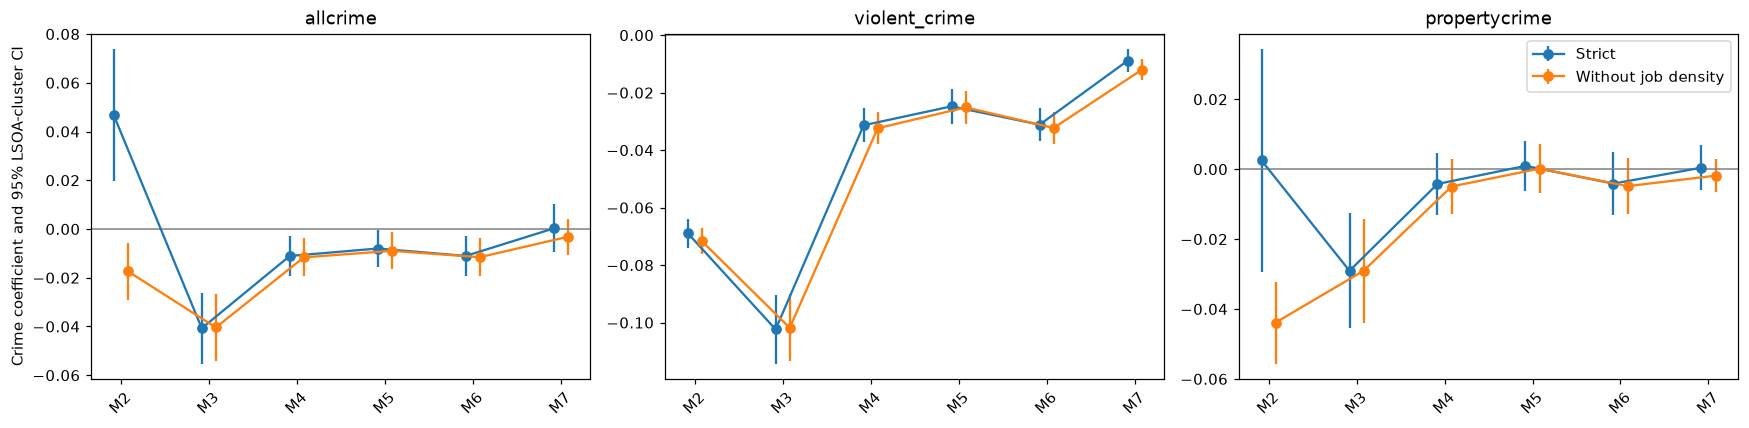

In [15]:
plot_models = [name for name,_,_,_ in model_specs(False) if name != 'M1']
fig,axes = plt.subplots(1,3,figsize=(16,4))
for ax,category in zip(axes,MAIN):
    for panel,results,offset in [('Strict',strict_results,-.08),('Without job density',expanded_results,.08)]:
        b=results.loc[results.crime.eq(category)].set_index('model').reindex(plot_models)
        ax.errorbar(np.arange(len(b))+offset,b.beta,
                    yerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o-',label=panel)
    ax.set_xticks(np.arange(len(plot_models)),plot_models,rotation=45)
    ax.set_title(category);ax.axhline(0,color='grey',linewidth=1)
axes[0].set_ylabel('Crime coefficient and 95% LSOA-cluster CI')
axes[-1].legend();fig.tight_layout();fig.savefig(OUT/'reconciled_coefficient_sequence.png',dpi=160);plt.show()

## 5. Individual main regressions and all control coefficients

Expand each regression to inspect crime and control estimates. All seven models appear here; no separate robustness section is needed. Economic controls are included through M7 when identified because no borough-year effects are included. M1 contains property characteristics only.

In [16]:
strict_coefficients = show_models(strict_results,'strict_models','strict_all_coefficients.csv')
expanded_coefficients = show_models(expanded_results,'without_jobdensity_models','without_jobdensity_all_coefficients.csv')

Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Detached (relative to flat),0.5849,0.0253,23.13,0.5353 to 0.6344,<0.001
Semi-detached (relative to flat),0.1272,0.0212,6.00,0.0856 to 0.1688,<0.001
Terraced (relative to flat),0.0990,0.0204,4.87,0.0591 to 0.1390,<0.001
Freehold,0.1278,0.0201,6.36,0.0884 to 0.1671,<0.001
New build,0.0630,0.0224,2.81,0.0191 to 0.1068,0.005
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime annual),0.0467,0.0138,3.38,0.0196 to 0.0738,<0.001
Detached (relative to flat),0.6070,0.0256,23.67,0.5567 to 0.6573,<0.001
Semi-detached (relative to flat),0.1430,0.0214,6.67,0.1010 to 0.1850,<0.001
Terraced (relative to flat),0.1030,0.0206,5.01,0.0627 to 0.1433,<0.001


Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Detached (relative to flat),0.5850,0.0250,23.40,0.5360 to 0.6341,<0.001
Semi-detached (relative to flat),0.1334,0.0208,6.42,0.0927 to 0.1742,<0.001
Terraced (relative to flat),0.1042,0.0199,5.23,0.0652 to 0.1433,<0.001
Freehold,0.1259,0.0197,6.40,0.0873 to 0.1645,<0.001
New build,0.0686,0.0224,3.06,0.0246 to 0.1126,0.002
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime annual),-0.0173,0.0060,-2.88,-0.0291 to -0.0055,0.004
Detached (relative to flat),0.5772,0.0248,23.28,0.5286 to 0.6258,<0.001
Semi-detached (relative to flat),0.1280,0.0206,6.22,0.0876 to 0.1684,<0.001
Terraced (relative to flat),0.1029,0.0198,5.19,0.0640 to 0.1418,<0.001


## 6. Interpretation and model numbering

This numbering supersedes the previous six-model and screenshot-based tables. Earlier results are archived; do not combine tables with different model definitions under the same labels.

M3 adds controls, year effects and local-authority effects together. M4 changes geographical granularity; M5 changes only the crime window relative to M4; M6 uses current crime and finer time effects relative to M4; M7 changes geographical granularity again. Lagged crime can still be endogenous. Neither fixed effects nor lagging establishes causality. Statistical insignificance is not proof of no effect, and comparing significance levels is not a test of a coefficient difference.

The data contain only one value of each economic variable per borough-year, but this does not automatically add borough-year effects. Here their separate slopes are estimated alongside the explicitly listed fixed effects. Sample restrictions and source/category definitions still limit generalisation.

The prior-twelve-month counts remain in the merged export for reference but are not regressed in this notebook. All model tables use supplied original annual or previous-calendar-year crime. New outputs are saved in `original_crime_models_outputs/`, keeping earlier MPS-based results separate.

## 7. External monthly MPS data (optional, after M1-M7)

This section reads, aggregates and merges the monthly file for coverage checks and comparison with supplied crime. It does not change the original-data regression estimates above. It constructs monthly, full calendar-year and prior-twelve-month measures for later analysis.

### 7.1 Read the monthly file


In [17]:
if not MONTHLY_FILE.is_file():
    raise FileNotFoundError('Stage 3 needs MPS LSOA Level Crime (Historical).csv in the project folder or project_data/.')
MPS = MONTHLY_FILE
raw = pd.read_csv(MPS, encoding='utf-8-sig')
raw.columns = raw.columns.str.strip()
print('Monthly file:', MPS)
print('SHA256:', hashlib.sha256(MPS.read_bytes()).hexdigest())
print('Category rows:', len(raw))

Monthly file: C:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project\project_data\MPS LSOA Level Crime (Historical).csv
SHA256: 9849c110ebb69c0c518126c09a60aa6f7fa5f5294ce22b28628c2e04c24de4fa
Category rows: 112977


### 7.2 Check dates and category rows

In [18]:
required = ['LSOA Code', 'Borough', 'Major Category', 'Minor Category']
assert set(required) <= set(raw.columns)
assert not raw.duplicated(['LSOA Code', 'Major Category', 'Minor Category']).any()
assert not raw[required].isna().any().any()
assert raw.groupby('LSOA Code').Borough.nunique().max() == 1
month_cols = sorted((c for c in raw if re.fullmatch('20\\d{2}(0[1-9]|1[0-2])', c)))
study_months = [c for c in month_cols if '201004' <= c <= '201512']
expected = pd.period_range('2010-04', '2015-12', freq='M').strftime('%Y%m').tolist()
assert study_months == expected, 'Missing study months: ' + str(set(expected) - set(study_months))
counts = raw[study_months].apply(pd.to_numeric, errors='raise')
assert counts.notna().all().all(), 'Inspect missing monthly cells before aggregation'
assert counts.ge(0).all().all() and (counts % 1).eq(0).all().all()
print('Source coverage:', month_cols[0], month_cols[-1], '; study months:', len(study_months))
table(raw.groupby('Major Category').agg(rows=('LSOA Code', 'size'), lsoas=('LSOA Code', 'nunique')), 'source_categories')
table(raw[['Major Category', 'Minor Category']].drop_duplicates().sort_values(['Major Category', 'Minor Category']), 'source_minor_categories')

Source coverage: 201004 202211 ; study months: 69
Showing 20 of 25 rows; the complete table is saved as source_minor_categories.csv.


,rows,lsoas
Major Category,,
ARSON AND CRIMINAL DAMAGE,9543,4988
BURGLARY,9974,4988
DRUG OFFENCES,9834,4988
MISCELLANEOUS CRIMES AGAINST SOCIETY,4983,4983
POSSESSION OF WEAPONS,4875,4875
PUBLIC ORDER OFFENCES,15504,4988
ROBBERY,9028,4983
THEFT,19026,4988
VEHICLE OFFENCES,19045,4988


,Major Category,Minor Category
0,ARSON AND CRIMINAL DAMAGE,ARSON
1,ARSON AND CRIMINAL DAMAGE,CRIMINAL DAMAGE
2,BURGLARY,BURGLARY BUSINESS AND COMMUNITY
3,BURGLARY,BURGLARY IN A DWELLING
4,DRUG OFFENCES,POSSESSION OF DRUGS
5,DRUG OFFENCES,TRAFFICKING OF DRUGS
6,MISCELLANEOUS CRIMES AGAINST SOCIETY,MISC CRIMES AGAINST SOCIETY
7,POSSESSION OF WEAPONS,POSSESSION OF WEAPONS
8,PUBLIC ORDER OFFENCES,OTHER OFFENCES PUBLIC ORDER
9,PUBLIC ORDER OFFENCES,PUBLIC FEAR ALARM OR DISTRESS


### 7.3 Monthly crime measures

All published offences; Violence Against the Person; and a property group comprising Burglary, Theft, Vehicle Offences, and Arson and Criminal Damage. Robbery is not included in that property group. Residential burglary is constructed but not used in the main regressions.

In [19]:
GROUPS = {'mps_all': None, 'mps_violence': ['VIOLENCE AGAINST THE PERSON'], 'mps_property': ['BURGLARY', 'THEFT', 'VEHICLE OFFENCES', 'ARSON AND CRIMINAL DAMAGE']}
series = {}
for name, categories in GROUPS.items():
    subset = raw if categories is None else raw.loc[raw['Major Category'].isin(categories)]
    wide = subset.groupby('LSOA Code')[study_months].sum(min_count=1)
    if categories is not None:
        complete = subset.groupby('LSOA Code')['Major Category'].nunique().eq(len(categories))
        wide = wide.where(complete, axis=0)
    series[name] = wide
series['mps_residential_burglary'] = raw.loc[raw['Minor Category'].eq('BURGLARY IN A DWELLING')].groupby('LSOA Code')[study_months].sum(min_count=1)
monthly_parts = []
for name, wide in series.items():
    long = wide.reset_index().melt(id_vars='LSOA Code', var_name='month_text', value_name=name)
    long['month'] = pd.to_datetime(long.pop('month_text'), format='%Y%m').dt.to_period('M')
    long = long.rename(columns={'LSOA Code': 'lsoacode'}).set_index(['lsoacode', 'month'])
    monthly_parts.append(long)
monthly = pd.concat(monthly_parts, axis=1).sort_index()
MEASURES = list(series)
table(monthly.groupby(level='month')[MEASURES].sum(min_count=1), 'monthly_source_totals')
monthly.reset_index().to_csv(OUT / 'lsoa_month_crime.csv.gz', index=False, compression={'method': 'gzip', 'compresslevel': 1})

Showing 20 of 69 rows; the complete table is saved as monthly_source_totals.csv.


,mps_all,mps_violence,mps_property,mps_residential_burglary
month,,,,
2010-04,64053,11648,42093,4307
2010-05,65951,12657,42334,4385
2010-06,66686,12830,43317,4380
2010-07,67704,12934,43497,4442
2010-08,62821,11251,40534,4517
2010-09,63553,11228,41953,4725
2010-10,66031,11332,43750,5057
2010-11,64530,10578,43700,6008
2010-12,54913,9959,36646,5523


### 7.4 Trailing exposure and geographical matching

In [20]:
grid = pd.MultiIndex.from_product([monthly.index.get_level_values('lsoacode').unique(), pd.period_range('2010-04', '2015-12', freq='M')], names=['lsoacode', 'month'])
monthly = monthly.reindex(grid)
exposure = monthly.copy()
for c in MEASURES:
    exposure[c + '_prior12'] = monthly.groupby(level='lsoacode')[c].transform(lambda s: s.shift(1).rolling(12, min_periods=12).sum())
exposure = exposure.reset_index().rename(columns={'month': 'sale_month'})
borough = raw[['LSOA Code', 'Borough']].drop_duplicates().rename(columns={'LSOA Code': 'lsoacode', 'Borough': 'mps_borough'})
df['sale_month'] = df.transactiondates.dt.to_period('M')
merged = df.merge(borough, on='lsoacode', how='left', validate='many_to_one')
merged = merged.merge(exposure, on=['lsoacode', 'sale_month'], how='left', validate='many_to_one', indicator='monthly_merge')
merged['mps_code_match'] = merged.lsoacode.isin(borough.lsoacode)
merged['mps_sale_month_match'] = merged.monthly_merge.eq('both')
merged['mps_borough_match'] = merged.oslaua.eq(merged.mps_borough)
merged['city_of_london'] = merged.oslaua.eq('E09000001')
merged['mps_geography_ok'] = merged.mps_code_match & merged.mps_borough_match & ~merged.city_of_london

### 7.5 Complete annual totals and matching coverage

Only exact LSOA codes are matched. External exposure is withheld for City of London and transaction/source borough mismatches. No original transaction is deleted from the merged export. Annual 2010 is missing because January–March are unavailable.

In [21]:
a = monthly.reset_index()
a['year'] = a.month.dt.year
group = a.groupby(['lsoacode', 'year'])
annual = group[MEASURES].sum(min_count=12).where(group[MEASURES].count().eq(12))
annual = annual.rename(columns={c: c + '_annual' for c in MEASURES}).reset_index()
merged = merged.merge(annual, on=['lsoacode', 'year'], how='left', validate='many_to_one')
external_columns = MEASURES + [c + '_prior12' for c in MEASURES] + [c + '_annual' for c in MEASURES]
merged.loc[~merged.mps_geography_ok, external_columns] = np.nan
assert len(merged) == len(df) and merged.transaction_id.is_unique
assert merged.loc[merged.sale_month.lt(pd.Period('2011-04', 'M')), 'mps_all_prior12'].isna().all()
assert merged.loc[merged.year.eq(2010), 'mps_all_annual'].isna().all()
assert merged.loc[merged.city_of_london, external_columns].isna().all().all()
coverage = merged.groupby('year').agg(N=('price', 'size'), code_match=('mps_code_match', 'mean'), geography_ok=('mps_geography_ok', 'mean'), prior12_available=('mps_all_prior12', lambda x: x.notna().mean()), annual_available=('mps_all_annual', lambda x: x.notna().mean()))
table(coverage, 'merge_coverage_by_year')
table(merged.groupby('la_name').agg(N=('price', 'size'), code_match=('mps_code_match', 'mean'), geography_ok=('mps_geography_ok', 'mean')), 'coverage_by_authority')
table(merged.loc[merged.mps_code_match & ~merged.mps_borough_match].groupby(['lsoacode', 'la_name', 'mps_borough']).size().to_frame('N'), 'borough_mismatch_transactions')
table(merged.loc[~merged.mps_code_match].groupby(['lsoacode', 'la_name']).size().to_frame('N'), 'unmatched_lsoas')
merged.to_csv(OUT / 'land_registry_crime_monthly_merged.csv.gz', index=False, compression={'method': 'gzip', 'compresslevel': 1})
print('Saved all', len(merged), 'transactions with monthly, annual and prior12 measures.')
print('Usable prior12 exposures:', merged.mps_all_prior12.notna().sum())

Showing 20 of 38 rows; the complete table is saved as coverage_by_authority.csv.
Showing 20 of 186 rows; the complete table is saved as unmatched_lsoas.csv.
Saved all 549813 transactions with monthly, annual and prior12 measures.
Usable prior12 exposures: 408094


,N,code_match,geography_ok,prior12_available,annual_available
year,,,,,
2010,91085,0.9404,0.9403,0.0000,0.0000
2011,89499,0.9378,0.9377,0.7460,0.9377
2012,91980,0.9286,0.9286,0.9286,0.9286
2013,110733,0.9240,0.9240,0.9240,0.9240
2014,117519,0.9211,0.9211,0.9211,0.9211
2015,48997,0.9256,0.9256,0.9256,0.9256


,N,code_match,geography_ok
la_name,,,
Barking and Dagenham,9080,0.8529,0.8529
Barnet,23699,0.9129,0.9129
Bexley,16683,0.9717,0.9717
Brent,12985,0.9630,0.9630
Bromley,27399,0.9870,0.9870
Camden,14419,0.9570,0.9570
City of London,1583,0.0000,0.0000
Croydon,23731,0.9267,0.9267
Ealing,18036,0.9581,0.9580


,,,N
lsoacode,la_name,mps_borough,
E01000804,Lewisham,E09000006,9
E01001071,Tandridge,E09000008,1
E01002564,Ealing,E09000018,2


,,N
lsoacode,la_name,
E01000001,City of London,172
E01000002,City of London,564
E01000003,City of London,184
E01000005,City of London,37
E01000010,Barking and Dagenham,266
E01000023,Barking and Dagenham,587
E01000048,Barking and Dagenham,9
E01000092,Barking and Dagenham,332
E01000109,Barking and Dagenham,85


### 7.6 Compare supplied and reconstructed annual crime

In [22]:
PAIRS = {'allcrime': 'mps_all', 'violent_crime': 'mps_violence', 'propertycrime': 'mps_property'}
area = merged.loc[merged.mps_geography_ok].groupby(['lsoacode', 'year'], as_index=False).first()
compare = []
for supplied, ext in PAIRS.items():
    for year, b in area.groupby('year'):
        valid = b[[supplied, ext + '_annual']].dropna()
        compare.append({'supplied': supplied, 'external': ext, 'year': year, 'lsoa_years': len(valid), 'supplied_mean': valid[supplied].mean(), 'external_mean': valid[ext + '_annual'].mean(), 'supplied_zero_share': valid[supplied].eq(0).mean(), 'external_zero_share': valid[ext + '_annual'].eq(0).mean(), 'correlation': valid[supplied].corr(valid[ext + '_annual']) if valid[supplied].nunique() > 1 and len(valid) > 2 else np.nan, 'exact_match_share': valid[supplied].eq(valid[ext + '_annual']).mean()})
table(pd.DataFrame(compare), 'supplied_vs_external_annual')

,supplied,external,year,lsoa_years,supplied_mean,external_mean,supplied_zero_share,external_zero_share,correlation,exact_match_share
0,allcrime,mps_all,2010,0,NaN,NaN,NaN,NaN,NaN,NaN
1,allcrime,mps_all,2011,4638,243.0226,149.3862,0.0000,0.0000,0.9482,0.0017
2,allcrime,mps_all,2012,4637,221.8352,143.3882,0.0000,0.0000,0.9590,0.0030
3,allcrime,mps_all,2013,4642,195.3175,133.9978,0.0000,0.0000,0.9646,0.0062
4,allcrime,mps_all,2014,4648,184.8853,132.8201,0.0000,0.0000,0.9645,0.0054
5,allcrime,mps_all,2015,4590,14.2425,139.8115,0.0000,0.0000,0.9322,0.0000
6,violent_crime,mps_violence,2010,0,NaN,NaN,NaN,NaN,NaN,NaN
7,violent_crime,mps_violence,2011,4638,29.5082,25.3894,0.0015,0.0026,0.9503,0.0755
8,violent_crime,mps_violence,2012,4637,26.9827,24.8631,0.0009,0.0011,0.9522,0.0766
9,violent_crime,mps_violence,2013,4642,8.2355,24.0952,0.0282,0.0011,0.9047,0.0114


## 8. Rerun M1-M7 using reconstructed MPS crime

These are separate results using annual totals reconstructed from the monthly file, not individual-month crime or prior-12-month exposure. Only M5 uses previous-calendar-year crime. All other crime models use current annual crime. Controls, fixed effects and LSOA clustering match the original-data sequence. Each panel uses one common sample across all models and categories. The shared lag requirement starts the MPS sample in 2012; job density restricts the strict panel to 2014, while the expanded panel extends to 2015. Missing coverage, City of London, borough mismatches and conflicting borough assignments are excluded.

The source's offence categories need not match the original definitions. Differences from original estimates combine measurement and sample changes. A positive or negative coefficient is an adjusted association, not a demonstrated causal effect.


In [23]:
# Preserve the original-data regression inputs before preparing the MPS panel.
original_model_data = data.copy()
original_main = MAIN.copy()
original_crime_columns = CRIME_COLUMNS.copy()
original_output_dir = OUT
OUT = INPUT_DIR / 'monthly_crime_models_outputs'
OUT.mkdir(parents=True, exist_ok=True)
MAIN = ['mps_all', 'mps_violence', 'mps_property']
external = merged[['transaction_id', 'mps_geography_ok'] + [c + '_annual' for c in MAIN]]
data = original_model_data.merge(external, on='transaction_id', how='left', validate='one_to_one')
previous_mps = annual[['lsoacode', 'year'] + [c + '_annual' for c in MAIN]].copy()
previous_mps['year'] += 1
previous_mps = previous_mps.rename(columns={c + '_annual': c + '_lagyear' for c in MAIN})
data = data.merge(previous_mps, on=['lsoacode', 'year'], how='left', validate='many_to_one')
data.loc[~data.mps_geography_ok, [c + '_lagyear' for c in MAIN]] = np.nan
CRIME_COLUMNS = []
for category in MAIN:
    for exposure in ['annual', 'lagyear']:
        name = 'log1p_' + category + '_' + exposure
        data[name] = np.log1p(data[category + '_' + exposure])
        CRIME_COLUMNS.append(name)
mps_strict = sequence_sample(True)
mps_expanded = sequence_sample(False)
mps_strict = mps_strict.loc[mps_strict.mps_geography_ok].copy()
mps_expanded = mps_expanded.loc[mps_expanded.mps_geography_ok].copy()
assert mps_strict.year.between(2012, 2014).all()
assert mps_expanded.year.between(2012, 2015).all()
table(pd.DataFrame({'strict':mps_strict.groupby('year').size(), 'without_jobdensity':mps_expanded.groupby('year').size()}).fillna(0).astype(int), 'mps_common_samples')


,strict,without_jobdensity
year,,
2012,85375,85375
2013,99429,99429
2014,108207,108207
2015,0,45336


In [24]:
mps_strict_results = estimate_specs(mps_strict, 'mps_strict', model_specs(True))
mps_expanded_results = estimate_specs(mps_expanded, 'mps_without_jobdensity', model_specs(False))


mps_strict: 19 regressions on 293,011 identical transactions.
mps_without_jobdensity: 19 regressions on 338,347 identical transactions.


### 8.1 Crime coefficients and all control estimates

Confidence intervals and p-values use LSOA-clustered standard errors. M1 has no crime coefficient. Expand the individual regressions below for all estimated control coefficients.


In [25]:
for label, results in [('MPS: job density included', mps_strict_results), ('MPS: job density omitted', mps_expanded_results)]:
    print(label)
    table(results.loc[results.model.ne('M1'), ['model','crime','crime_exposure','N','beta','se','ci_low','ci_high','p']], label.replace(':','').replace(' ','_').lower())
mps_strict_coefficients = show_models(mps_strict_results, 'mps_strict_models', 'mps_strict_all_coefficients.csv')
mps_expanded_coefficients = show_models(mps_expanded_results, 'mps_without_jobdensity_models', 'mps_without_jobdensity_all_coefficients.csv')
for results in [mps_strict_results, mps_expanded_results]:
    assert len(results) == 19 and results.N.nunique() == 1
    assert results.loc[results.model.eq('M5'), 'crime_exposure'].eq('lagyear').all()
    assert results.loc[results.model.isin(['M2','M3','M4','M6','M7']), 'crime_exposure'].eq('annual').all()
print('Verified: common samples, 19 regressions per panel, and lagged crime only in M5.')
# Restore original-data inputs; MPS tables remain in their separate output directory.
data = original_model_data
MAIN = original_main
CRIME_COLUMNS = original_crime_columns
OUT = original_output_dir


MPS: job density included
MPS: job density omitted
Verified: common samples, 19 regressions per panel, and lagged crime only in M5.


,model,crime,crime_exposure,N,beta,se,ci_low,ci_high,p
1,M2,mps_all,annual,293011,0.1296,0.0149,0.1004,0.1589,4.9829e-18
2,M2,mps_violence,annual,293011,-0.0966,0.0129,-0.1220,-0.0713,8.6646e-14
3,M2,mps_property,annual,293011,0.2059,0.0138,0.1789,0.2329,2.0193e-49
4,M3,mps_all,annual,293011,-0.0292,0.0091,-0.0471,-0.0113,1.3921e-03
5,M3,mps_violence,annual,293011,-0.1474,0.0081,-0.1633,-0.1315,2.9620e-71
6,M3,mps_property,annual,293011,0.0404,0.0080,0.0247,0.0560,4.5484e-07
7,M4,mps_all,annual,293011,-0.0093,0.0052,-0.0195,0.0010,7.5932e-02
8,M4,mps_violence,annual,293011,-0.0502,0.0043,-0.0586,-0.0419,1.5483e-31
9,M4,mps_property,annual,293011,0.0109,0.0049,0.0012,0.0206,2.7998e-02
10,M5,mps_all,lagyear,293011,-0.0078,0.0053,-0.0181,0.0026,1.4008e-01


,model,crime,crime_exposure,N,beta,se,ci_low,ci_high,p
1,M2,mps_all,annual,338347,0.1248,0.0146,9.6195e-02,0.1535,1.7504e-17
2,M2,mps_violence,annual,338347,-0.0879,0.0124,-1.1229e-01,-0.0635,1.9201e-12
3,M2,mps_property,annual,338347,0.1998,0.0135,1.7337e-01,0.2262,1.3708e-48
4,M3,mps_all,annual,338347,-0.0326,0.0088,-4.9914e-02,-0.0152,2.3627e-04
5,M3,mps_violence,annual,338347,-0.1473,0.0079,-1.6271e-01,-0.1319,1.1611e-75
6,M3,mps_property,annual,338347,0.0373,0.0078,2.2077e-02,0.0525,1.5941e-06
7,M4,mps_all,annual,338347,-0.0107,0.0050,-2.0572e-02,-0.0008,3.3285e-02
8,M4,mps_violence,annual,338347,-0.0509,0.0041,-5.8938e-02,-0.0428,1.6071e-34
9,M4,mps_property,annual,338347,0.0093,0.0047,2.7253e-05,0.0186,4.9333e-02
10,M5,mps_all,lagyear,338347,-0.0093,0.0051,-1.9273e-02,0.0007,6.7144e-02


Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Detached (relative to flat),0.6105,0.0278,21.99,0.5561 to 0.6649,<0.001
Semi-detached (relative to flat),0.1635,0.0239,6.85,0.1167 to 0.2103,<0.001
Terraced (relative to flat),0.1369,0.0231,5.94,0.0917 to 0.1821,<0.001
Freehold,0.0972,0.0228,4.26,0.0525 to 0.1419,<0.001
New build,0.0809,0.0274,2.95,0.0271 to 0.1346,0.003
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + mps all annual),0.1296,0.0149,8.69,0.1004 to 0.1589,<0.001
Detached (relative to flat),0.6705,0.0277,24.17,0.6161 to 0.7249,<0.001
Semi-detached (relative to flat),0.2082,0.0237,8.79,0.1618 to 0.2546,<0.001
Terraced (relative to flat),0.1503,0.0228,6.59,0.1056 to 0.1950,<0.001


Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Detached (relative to flat),0.6112,0.0271,22.53,0.5581 to 0.6644,<0.001
Semi-detached (relative to flat),0.1706,0.0230,7.42,0.1255 to 0.2157,<0.001
Terraced (relative to flat),0.1421,0.0222,6.40,0.0986 to 0.1856,<0.001
Freehold,0.0962,0.0219,4.39,0.0532 to 0.1392,<0.001
New build,0.0887,0.0278,3.19,0.0341 to 0.1433,0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + mps all annual),0.1248,0.0146,8.54,0.0962 to 0.1535,<0.001
Detached (relative to flat),0.6699,0.0272,24.64,0.6166 to 0.7232,<0.001
Semi-detached (relative to flat),0.2138,0.0229,9.34,0.1689 to 0.2587,<0.001
Terraced (relative to flat),0.1554,0.0220,7.06,0.1122 to 0.1985,<0.001


### 8.2 Findings from the completed MPS rerun

The strict panel contains 293,011 sales (2012-2014); the panel without job density contains 338,347 (2012-2015). These panels differ in both controls and time coverage.

In the expanded panel, M4 (MSOA and year effects) estimates -0.01071 for all crime (p=0.033), -0.05087 for violence (p<0.001), and +0.00933 for property crime (p=0.049). M5 changes only crime to the previous calendar year: -0.00931 for all crime (p=0.067), -0.04898 for violence (p<0.001), and +0.00936 for property crime (p=0.053). Lagging therefore does not turn every association negative.

M7 uses current annual crime, LSOA effects and year-quarter effects. In the expanded panel:

| Crime | Coefficient | 95% clustered CI | p-value |
|---|---:|---|---:|
| All published crime | 0.00574 | -0.00442 to 0.01591 | 0.268 |
| Violence | 0.00067 | -0.00490 to 0.00624 | 0.815 |
| Property group | 0.00739 | -0.00118 to 0.01597 | 0.091 |

All three M7 intervals include zero. The strict-panel M7 intervals also include zero. The negative violence association in MSOA models does not persist with finer LSOA effects. This is consistent with persistent differences between LSOAs contributing to the MSOA estimate, but does not establish the explanation: finer effects also change the identifying variation and precision. Positive property coefficients may reflect remaining confounding, exposure differences or measurement. These results do not prove crime increases prices, nor does insignificance prove no effect.

Coefficients apply to log(1 + crime), not exactly log(crime). The custom estimator clusters by LSOA and uses a cluster-count correction; it does not apply an additional absorbed-fixed-effect degrees-of-freedom correction.
